# Notebook 01b — Kaggle Wikipedia Movie Plots Audit + CMU Comparison

**Project:** Scènes à Faire Computational Framework (v4 rebuild)  
**Purpose:** Run the same audit as Notebook 01 on the Kaggle Wikipedia Movie Plots dataset, then compare the two corpora side by side.

**Why this notebook exists:** Notebook 01 revealed that CMU effectively ends in 2013. The Kaggle Wikipedia Movie Plots dataset runs several years further and is a natural replication corpus. Before committing to either as primary, we need to see them compared head-to-head.

**Prerequisite:** Download `wiki_movie_plots_deduped.csv` from https://www.kaggle.com/datasets/jrobischon/wikipedia-movie-plots and upload to `MyDrive/DGK Lab/Reasoning Lab/DGK Lab - Scene A Faire Computational/Data/WikipediaMoviePlots/`.

**Output:**
1. `kaggle_audited.parquet` — cleaned Kaggle corpus using the same schema as `cmu_audited.parquet`
2. Side-by-side comparison: year coverage, decade density, title overlap, genre distributions
3. A decision-ready recommendation for how to use the two corpora together

## 1. Setup

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!pip install -q tiktoken pyarrow

In [ ]:
import os
import re
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    import tiktoken
    HAS_TIKTOKEN = True
except ImportError:
    HAS_TIKTOKEN = False

plt.rcParams['figure.dpi'] = 100
plt.rcParams['figure.facecolor'] = 'white'
pd.set_option('display.max_colwidth', 120)

In [ ]:
PROJECT_ROOT = '/content/drive/MyDrive/DGK Lab/Reasoning Lab/DGK Lab - Scene A Faire Computational'

KAGGLE_CSV_PATH = f'{PROJECT_ROOT}/Data/WikipediaMoviePlots/wiki_movie_plots_deduped.csv'
CMU_AUDITED_PATH = f'{PROJECT_ROOT}/v4_rebuild/01_audit/cmu_audited.parquet'

OUTPUT_DIR = f'{PROJECT_ROOT}/v4_rebuild/01b_audit_kaggle'
FIGURES_DIR = f'{OUTPUT_DIR}/figures'

os.makedirs(OUTPUT_DIR, exist_ok=True)
os.makedirs(FIGURES_DIR, exist_ok=True)

# Sanity check that both files exist before proceeding
assert os.path.exists(KAGGLE_CSV_PATH), f'Kaggle CSV not found at {KAGGLE_CSV_PATH}. Download from https://www.kaggle.com/datasets/jrobischon/wikipedia-movie-plots and upload.'
assert os.path.exists(CMU_AUDITED_PATH), f'CMU audited parquet not found at {CMU_AUDITED_PATH}. Run Notebook 01 first.'

print(f'Kaggle CSV:   {KAGGLE_CSV_PATH}')
print(f'CMU parquet:  {CMU_AUDITED_PATH}')
print(f'Output dir:   {OUTPUT_DIR}')

Kaggle CSV:   /content/drive/MyDrive/DGK Lab/Reasoning Lab/DGK Lab - Scene A Faire Computational/Data/WikipediaMoviePlots/wiki_movie_plots_deduped.csv
CMU parquet:  /content/drive/MyDrive/DGK Lab/Reasoning Lab/DGK Lab - Scene A Faire Computational/v4_rebuild/01_audit/cmu_audited.parquet
Output dir:   /content/drive/MyDrive/DGK Lab/Reasoning Lab/DGK Lab - Scene A Faire Computational/v4_rebuild/01b_audit_kaggle


## 2. Load Kaggle Wikipedia Movie Plots

The Kaggle dataset has a different schema than CMU. We rename columns to match CMU's conventions so the downstream analysis can use the same code.

In [ ]:
print('Loading Wikipedia Movie Plots (Kaggle)...')
kaggle = pd.read_csv(KAGGLE_CSV_PATH)
print(f'  Loaded {len(kaggle):,} rows')
print(f'  Columns: {list(kaggle.columns)}')

# Rename columns to match CMU conventions
column_mapping = {
    'Release Year': 'year',
    'Title': 'name',
    'Origin/Ethnicity': 'origin',
    'Director': 'director',
    'Cast': 'cast',
    'Genre': 'genre_raw',
    'Wiki Page': 'wiki_page',
    'Plot': 'plot'
}
kaggle = kaggle.rename(columns=column_mapping)

# Create a stable surrogate ID from the wiki page URL
kaggle['wiki_id'] = kaggle['wiki_page'].apply(
    lambda u: str(u).split('/')[-1] if pd.notna(u) else None
)

print(f'\nSample row:')
print(kaggle.iloc[0][['wiki_id', 'name', 'year', 'origin', 'genre_raw']].to_string())

Loading Wikipedia Movie Plots (Kaggle)...
  Loaded 34,886 rows
  Columns: ['Release Year', 'Title', 'Origin/Ethnicity', 'Director', 'Cast', 'Genre', 'Wiki Page', 'Plot']

Sample row:
wiki_id      Kansas_Saloon_Smashers
name         Kansas Saloon Smashers
year                           1901
origin                     American
genre_raw                   unknown


## 3. Parse Year and Basic Filtering

In [ ]:
kaggle['year'] = pd.to_numeric(kaggle['year'], errors='coerce')
kaggle.loc[(kaggle['year'] < 1890) | (kaggle['year'] > 2025), 'year'] = np.nan
kaggle['decade'] = (kaggle['year'] // 10 * 10).astype('Int64')

valid_year = kaggle['year'].notna().sum()
print(f'Rows with valid year: {valid_year:,} ({valid_year/len(kaggle)*100:.1f}%)')
if valid_year > 0:
    print(f'Year range: {int(kaggle["year"].min())} – {int(kaggle["year"].max())}')

Rows with valid year: 34,886 (100.0%)
Year range: 1901 – 2017


## 4. Parse and Canonicalize Genres

Kaggle stores genres as comma-separated (or slash-separated) strings rather than CMU's JSON format. We split them and run the same 17-genre canonicalizer used in Notebook 01.

In [ ]:
def parse_kaggle_genres(genre_str):
    """Split Kaggle genre strings on common delimiters. 'unknown' → empty list."""
    if pd.isna(genre_str) or not genre_str:
        return []
    s = str(genre_str).strip().lower()
    if s in ('unknown', '-', 'none', 'n/a'):
        return []
    parts = re.split(r'[,;/]', s)
    return [p.strip() for p in parts if p.strip()]

kaggle['genres_parsed'] = kaggle['genre_raw'].apply(parse_kaggle_genres)
kaggle['n_raw_genres'] = kaggle['genres_parsed'].str.len()

print(f'Films with at least one raw genre: {(kaggle["n_raw_genres"] > 0).sum():,}')
print(f'Films with "unknown"/empty genre:  {(kaggle["n_raw_genres"] == 0).sum():,}')

raw_counter = Counter()
for glist in kaggle['genres_parsed']:
    raw_counter.update(glist)

print(f'\nTop 25 raw genre labels in Kaggle:')
for genre, count in raw_counter.most_common(25):
    print(f'  {count:>6,}  {genre}')

Films with at least one raw genre: 28,772
Films with "unknown"/empty genre:  6,114

Top 25 raw genre labels in Kaggle:
   7,913  drama
   5,799  comedy
   2,108  action
   1,811  romance
   1,450  horror
   1,420  thriller
     988  crime
     936  western
     777  adventure
     746  musical
     504  family
     504  science fiction
     493  romantic comedy
     476  crime drama
     463  fantasy
     462  mystery
     405  war
     361  sci-fi
     347  film noir
     330  animation
     297  biography
     255  animated
     173  comedy-drama
     154  musical comedy
     145  suspense


In [ ]:
# Same 17-genre canonicalization scheme as Notebook 01
CANONICAL_GENRES = [
    'Action', 'Adventure', 'Animation', 'Comedy', 'Crime',
    'Drama', 'Family', 'Fantasy', 'History', 'Horror',
    'Music', 'Mystery', 'Romance', 'Science Fiction',
    'Thriller', 'War', 'Western'
]

GENRE_KEYWORDS = {
    'Action':          ['action', 'martial arts'],
    'Adventure':       ['adventure', 'swashbuckler'],
    'Animation':       ['animation', 'animated', 'anime'],
    'Comedy':          ['comedy', 'comic', 'parody', 'satire', 'screwball', 'farce'],
    'Crime':           ['crime', 'gangster', 'heist', 'detective', 'whodunit', 'caper'],
    'Drama':           ['drama', 'melodrama'],
    'Family':          ['family', 'children'],
    'Fantasy':         ['fantasy', 'mythological', 'sword and sorcery'],
    'History':         ['history', 'historical', 'biographical', 'biography', 'period', 'docudrama'],
    'Horror':          ['horror', 'slasher', 'zombie', 'vampire', 'splatter'],
    'Music':           ['music', 'musical', 'concert'],
    'Mystery':         ['mystery', 'noir'],
    'Romance':         ['romance', 'romantic'],
    'Science Fiction': ['science fiction', 'sci-fi', 'scifi', 'cyberpunk', 'space opera'],
    'Thriller':        ['thriller', 'suspense', 'psychological'],
    'War':             ['war', 'military', 'combat'],
    'Western':         ['western']
}

def canonicalize(raw_genres):
    canonical = set()
    for raw in raw_genres:
        raw_lower = str(raw).lower()
        for canon, keywords in GENRE_KEYWORDS.items():
            if any(kw in raw_lower for kw in keywords):
                canonical.add(canon)
    return sorted(canonical)

kaggle['genres_canonical'] = kaggle['genres_parsed'].apply(canonicalize)
kaggle['n_canonical_genres'] = kaggle['genres_canonical'].str.len()

print(f'Canonicalization results:')
print(f'  Films with canonical genre: {(kaggle["n_canonical_genres"] > 0).sum():,}')
print(f'  Films with zero canonical:  {(kaggle["n_canonical_genres"] == 0).sum():,}')

canon_counter = Counter()
for glist in kaggle['genres_canonical']:
    canon_counter.update(glist)

max_count = max(canon_counter.values()) if canon_counter else 1
print(f'\nKaggle canonical genre distribution:')
for genre in CANONICAL_GENRES:
    count = canon_counter[genre]
    bar = '█' * int(count / max_count * 40)
    print(f'  {genre:<18} {count:>6,}  {bar}')

Canonicalization results:
  Films with canonical genre: 27,699
  Films with zero canonical:  7,187

Kaggle canonical genre distribution:
  Action              2,511  ██████████
  Adventure             878  ███
  Animation             909  ███
  Comedy              7,299  ██████████████████████████████
  Crime               1,635  ██████
  Drama               9,475  ████████████████████████████████████████
  Family                684  ██
  Fantasy               549  ██
  History               644  ██
  Horror              1,610  ██████
  Music                 967  ████
  Mystery               838  ███
  Romance             2,620  ███████████
  Science Fiction       933  ███
  Thriller            1,921  ████████
  War                   617  ██
  Western               974  ████


## 5. Plot Length Analysis

In [ ]:
kaggle['char_count'] = kaggle['plot'].str.len().fillna(0).astype(int)
kaggle['word_count'] = kaggle['plot'].str.split().str.len().fillna(0).astype(int)

if HAS_TIKTOKEN:
    print('Computing token counts with tiktoken cl100k_base...')
    enc = tiktoken.get_encoding('cl100k_base')
    kaggle['token_count'] = kaggle['plot'].apply(
        lambda x: len(enc.encode(x)) if isinstance(x, str) and x else 0
    )
else:
    kaggle['token_count'] = (kaggle['word_count'] * 1.33).astype(int)

print('\nKaggle plot length statistics:')
print('\nWords:')
print(kaggle['word_count'].describe().round(0).to_string())
print('\nTokens:')
print(kaggle['token_count'].describe().round(0).to_string())

print('\nToken count percentiles:')
for p in [50, 75, 90, 95, 99, 99.9]:
    v = np.percentile(kaggle['token_count'].dropna(), p)
    print(f'  p{p}: {v:>6,.0f} tokens')

Computing token counts with tiktoken cl100k_base...

Kaggle plot length statistics:

Words:
count    34886.0
mean       372.0
std        316.0
min          2.0
25%        122.0
50%        284.0
75%        581.0
max       6752.0

Tokens:
count    34886.0
mean       481.0
std        402.0
min          3.0
25%        162.0
50%        372.0
75%        744.0
max       8560.0

Token count percentiles:
  p50:    372 tokens
  p75:    744 tokens
  p90:    989 tokens
  p95:  1,160 tokens
  p99:  1,665 tokens
  p99.9:  2,841 tokens


## 6. Temporal Coverage

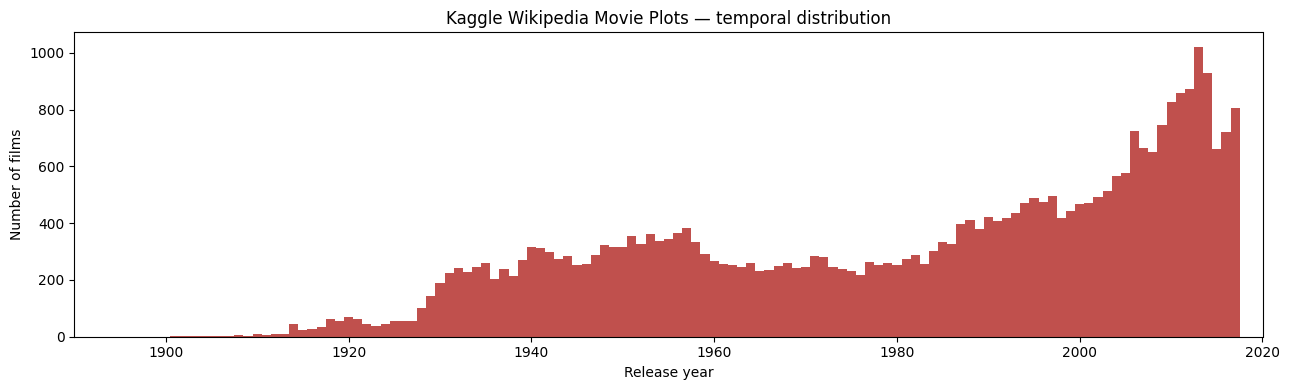


Films per decade:
  1900s:     26  
  1910s:    283  ██
  1920s:    671  █████
  1930s:  2,310  █████████████████
  1940s:  2,919  █████████████████████
  1950s:  3,414  █████████████████████████
  1960s:  2,497  ██████████████████
  1970s:  2,519  ██████████████████
  1980s:  3,219  ████████████████████████
  1990s:  4,468  █████████████████████████████████
  2000s:  5,866  ███████████████████████████████████████████
  2010s:  6,694  ██████████████████████████████████████████████████


In [ ]:
fig, ax = plt.subplots(1, 1, figsize=(13, 4))
year_series = kaggle['year'].dropna().astype(int)
year_counts = year_series.groupby(year_series).size()
ax.bar(year_counts.index, year_counts.values, color='#C0504D', edgecolor='none', width=1)
ax.set_xlabel('Release year')
ax.set_ylabel('Number of films')
ax.set_title('Kaggle Wikipedia Movie Plots — temporal distribution')
ax.set_xlim(1890, 2020)
plt.tight_layout()
plt.savefig(f'{FIGURES_DIR}/year_distribution_kaggle.png', dpi=150, bbox_inches='tight')
plt.show()

print('\nFilms per decade:')
decade_counts = kaggle.dropna(subset=['decade']).groupby('decade').size()
max_count = decade_counts.max()
for decade, count in decade_counts.items():
    bar = '█' * int(count / max_count * 50)
    print(f'  {int(decade)}s: {count:>6,}  {bar}')

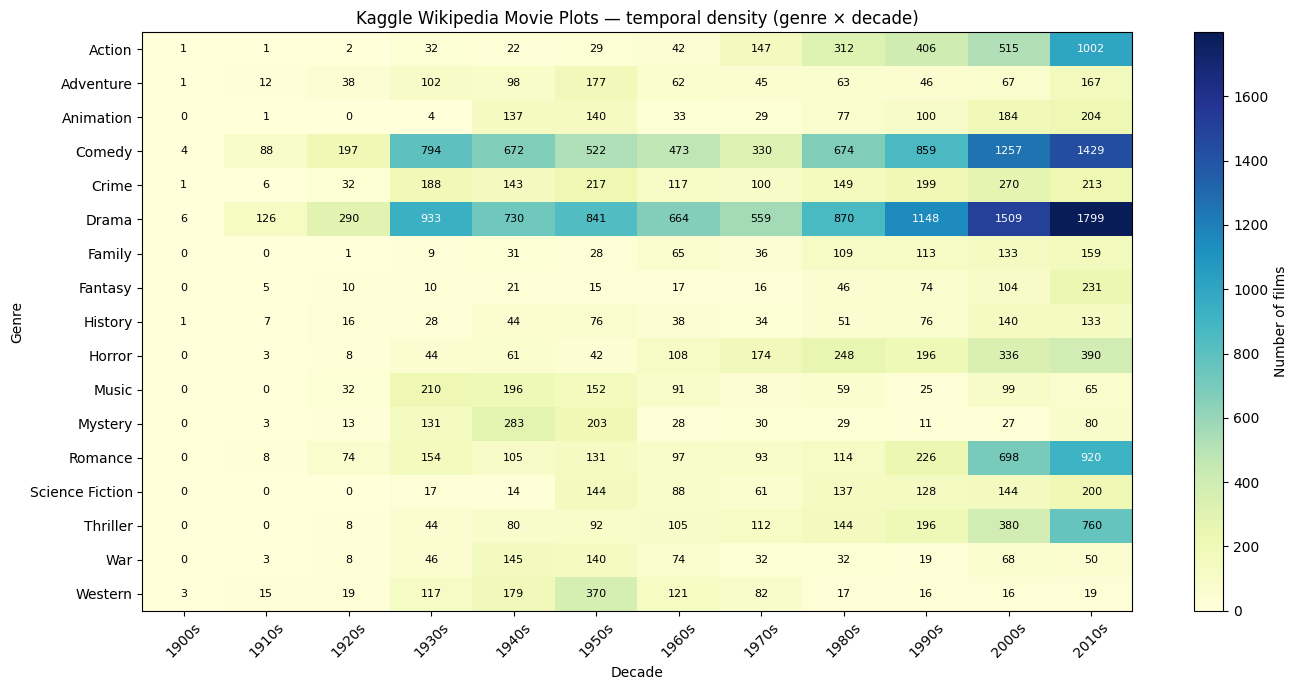

In [ ]:
# Genre × decade heatmap for Kaggle
exploded = (kaggle[kaggle['n_canonical_genres'] > 0]
            .dropna(subset=['decade'])
            .explode('genres_canonical'))

heatmap_data_k = exploded.pivot_table(
    index='genres_canonical',
    columns='decade',
    values='wiki_id',
    aggfunc='count',
    fill_value=0
)
heatmap_data_k = heatmap_data_k.reindex([g for g in CANONICAL_GENRES if g in heatmap_data_k.index])

fig, ax = plt.subplots(figsize=(14, 7))
im = ax.imshow(heatmap_data_k.values, aspect='auto', cmap='YlGnBu')
ax.set_xticks(range(len(heatmap_data_k.columns)))
ax.set_xticklabels([f'{int(d)}s' for d in heatmap_data_k.columns], rotation=45)
ax.set_yticks(range(len(heatmap_data_k.index)))
ax.set_yticklabels(heatmap_data_k.index)

vmax = heatmap_data_k.values.max()
for i in range(len(heatmap_data_k.index)):
    for j in range(len(heatmap_data_k.columns)):
        value = heatmap_data_k.values[i, j]
        color = 'white' if value > vmax * 0.5 else 'black'
        ax.text(j, i, f'{int(value)}', ha='center', va='center', color=color, fontsize=8)

plt.colorbar(im, ax=ax, label='Number of films')
ax.set_title('Kaggle Wikipedia Movie Plots — temporal density (genre × decade)')
ax.set_xlabel('Decade')
ax.set_ylabel('Genre')
plt.tight_layout()
plt.savefig(f'{FIGURES_DIR}/genre_decade_heatmap_kaggle.png', dpi=150, bbox_inches='tight')
plt.show()

## 7. Save Cleaned Kaggle Corpus

In [ ]:
cleaned_k = kaggle[
    (kaggle['word_count'] >= 50) &
    (kaggle['n_canonical_genres'] > 0) &
    (kaggle['plot'].notna()) &
    (kaggle['plot'].str.len() > 0)
].copy()

keep_cols = [
    'wiki_id', 'name', 'year', 'decade',
    'plot', 'char_count', 'word_count', 'token_count',
    'genres_parsed', 'genres_canonical', 'n_canonical_genres',
    'origin', 'director'
]
cleaned_k = cleaned_k[keep_cols].reset_index(drop=True)

output_path = f'{OUTPUT_DIR}/kaggle_audited.parquet'
cleaned_k.to_parquet(output_path, engine='pyarrow', compression='snappy')

print(f'Saved cleaned Kaggle corpus:')
print(f'  Path: {output_path}')
print(f'  Rows: {len(cleaned_k):,}  (from {len(kaggle):,} raw, {len(cleaned_k)/len(kaggle)*100:.1f}% retained)')
print(f'  Size: {os.path.getsize(output_path) / 1e6:.1f} MB')

Saved cleaned Kaggle corpus:
  Path: /content/drive/MyDrive/DGK Lab/Reasoning Lab/DGK Lab - Scene A Faire Computational/v4_rebuild/01b_audit_kaggle/kaggle_audited.parquet
  Rows: 25,557  (from 34,886 raw, 73.3% retained)
  Size: 39.5 MB


## 8. Cross-Corpus Comparison

Now we load the audited CMU corpus from Notebook 01 and compare it to the Kaggle corpus we just built. The three things we want to know:

1. **Temporal coverage** — does Kaggle cover years that CMU misses?
2. **Title overlap** — how many films appear in both corpora vs. unique to each?
3. **Genre distribution** — do the two corpora give similar or different pictures of each genre?

In [ ]:
print('Loading CMU audited corpus...')
cmu = pd.read_parquet(CMU_AUDITED_PATH)
print(f'  CMU:    {len(cmu):,} films')
print(f'  Kaggle: {len(cleaned_k):,} films')

print(f'\nYear coverage:')
for name, df_ in [('CMU   ', cmu), ('Kaggle', cleaned_k)]:
    years = df_['year'].dropna()
    if len(years) > 0:
        print(f'  {name}: {int(years.min())}–{int(years.max())}  '
              f'(median {int(years.median())}, 2010s count: {((years >= 2010) & (years < 2020)).sum():,})')

Loading CMU audited corpus...
  CMU:    35,249 films
  Kaggle: 25,557 films

Year coverage:
  CMU   : 1895–2014  (median 1993, 2010s count: 2,735)
  Kaggle: 1903–2017  (median 1987, 2010s count: 4,756)


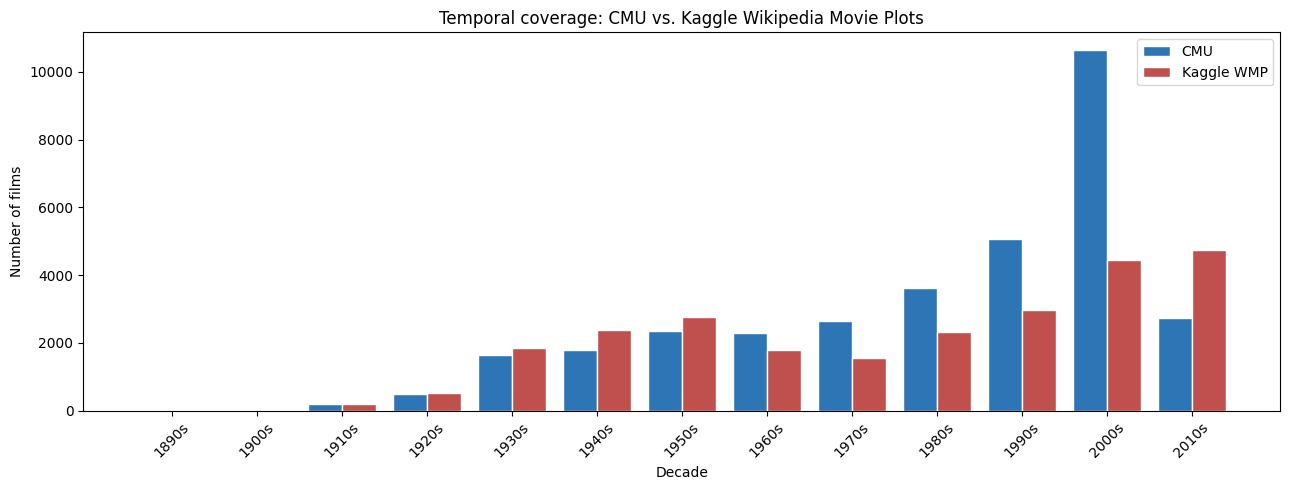


Decade-by-decade counts:
Decade          CMU   Kaggle   Kaggle−CMU
------------------------------------------
1890s             6        0           -6
1900s            20       10          -10
1910s           188      212          +24
1920s           503      526          +23
1930s         1,633    1,858         +225
1940s         1,781    2,377         +596 *
1950s         2,352    2,752         +400
1960s         2,284    1,802         -482
1970s         2,648    1,546       -1,102
1980s         3,612    2,309       -1,303
1990s         5,057    2,968       -2,089
2000s        10,631    4,441       -6,190
2010s         2,735    4,756       +2,021 *


In [ ]:
# Side-by-side decade comparison
cmu_decades = cmu.dropna(subset=['decade']).groupby('decade').size()
kaggle_decades = cleaned_k.dropna(subset=['decade']).groupby('decade').size()

all_decades = sorted(set(cmu_decades.index) | set(kaggle_decades.index))

fig, ax = plt.subplots(figsize=(13, 5))
width = 4
x = [float(d) for d in all_decades]
ax.bar([xi - width/2 for xi in x], [cmu_decades.get(d, 0) for d in all_decades],
       width=width, label='CMU', color='#2E75B6', edgecolor='white')
ax.bar([xi + width/2 for xi in x], [kaggle_decades.get(d, 0) for d in all_decades],
       width=width, label='Kaggle WMP', color='#C0504D', edgecolor='white')
ax.set_xlabel('Decade')
ax.set_ylabel('Number of films')
ax.set_title('Temporal coverage: CMU vs. Kaggle Wikipedia Movie Plots')
ax.legend()
ax.set_xticks(x)
ax.set_xticklabels([f'{int(d)}s' for d in all_decades], rotation=45)
plt.tight_layout()
plt.savefig(f'{FIGURES_DIR}/corpus_comparison_decades.png', dpi=150, bbox_inches='tight')
plt.show()

# Tabular form
print('\nDecade-by-decade counts:')
print(f'{"Decade":<10} {"CMU":>8} {"Kaggle":>8} {"Kaggle−CMU":>12}')
print('-' * 42)
for d in all_decades:
    c = cmu_decades.get(d, 0)
    k = kaggle_decades.get(d, 0)
    diff = k - c
    marker = ' *' if diff > 500 else ''
    print(f'{int(d)}s{" ":<6}{c:>8,} {k:>8,} {diff:>+12,}{marker}')

In [ ]:
# Title + year overlap estimation
# Normalize titles to handle punctuation, parentheticals, case
def normalize_title(t):
    if pd.isna(t):
        return ''
    t = str(t).lower()
    t = re.sub(r'\(.*?\)', '', t)          # drop parentheticals like '(film)', '(1990)'
    t = re.sub(r'[^a-z0-9\s]', '', t)       # strip punctuation
    t = re.sub(r'\s+', ' ', t).strip()
    return t

cmu_matching = cmu[['name', 'year']].copy()
cmu_matching['title_norm'] = cmu_matching['name'].apply(normalize_title)
cmu_matching['year_int'] = cmu_matching['year'].fillna(-1).astype(int)

kag_matching = cleaned_k[['name', 'year']].copy()
kag_matching['title_norm'] = kag_matching['name'].apply(normalize_title)
kag_matching['year_int'] = kag_matching['year'].fillna(-1).astype(int)

# Build match keys. Use title+year but also allow ±1 year slack.
cmu_keys = set(zip(cmu_matching['title_norm'], cmu_matching['year_int']))
kag_keys = set(zip(kag_matching['title_norm'], kag_matching['year_int']))

# Strict overlap (same title AND same year)
strict_overlap = cmu_keys & kag_keys

# Fuzzy overlap: allow ±1 year
cmu_titles = cmu_matching.groupby('title_norm')['year_int'].apply(set).to_dict()
kag_titles = kag_matching.groupby('title_norm')['year_int'].apply(set).to_dict()
fuzzy_matches = 0
shared_titles = set(cmu_titles.keys()) & set(kag_titles.keys())
for t in shared_titles:
    if t == '':
        continue
    cmu_years = cmu_titles[t]
    kag_years = kag_titles[t]
    # Match if any year pair is within ±1
    for cy in cmu_years:
        if any(abs(cy - ky) <= 1 for ky in kag_years):
            fuzzy_matches += 1
            break

print('Cross-corpus title matching:')
print(f'  Strict (title + exact year):  {len(strict_overlap):>6,} matches')
print(f'  Fuzzy (title + year ±1):      {fuzzy_matches:>6,} matches')
print(f'  CMU films total:              {len(cmu):>6,}')
print(f'  Kaggle films total:           {len(cleaned_k):>6,}')
print(f'  Est. unique films (union):    {len(cmu) + len(cleaned_k) - fuzzy_matches:>6,}')

overlap_rate_cmu = fuzzy_matches / len(cmu) * 100
overlap_rate_kag = fuzzy_matches / len(cleaned_k) * 100
print(f'\n  % of CMU    in Kaggle: {overlap_rate_cmu:.1f}%')
print(f'  % of Kaggle in CMU:    {overlap_rate_kag:.1f}%')

Cross-corpus title matching:
  Strict (title + exact year):  14,398 matches
  Fuzzy (title + year ±1):      14,412 matches
  CMU films total:              35,249
  Kaggle films total:           25,557
  Est. unique films (union):    46,394

  % of CMU    in Kaggle: 40.9%
  % of Kaggle in CMU:    56.4%


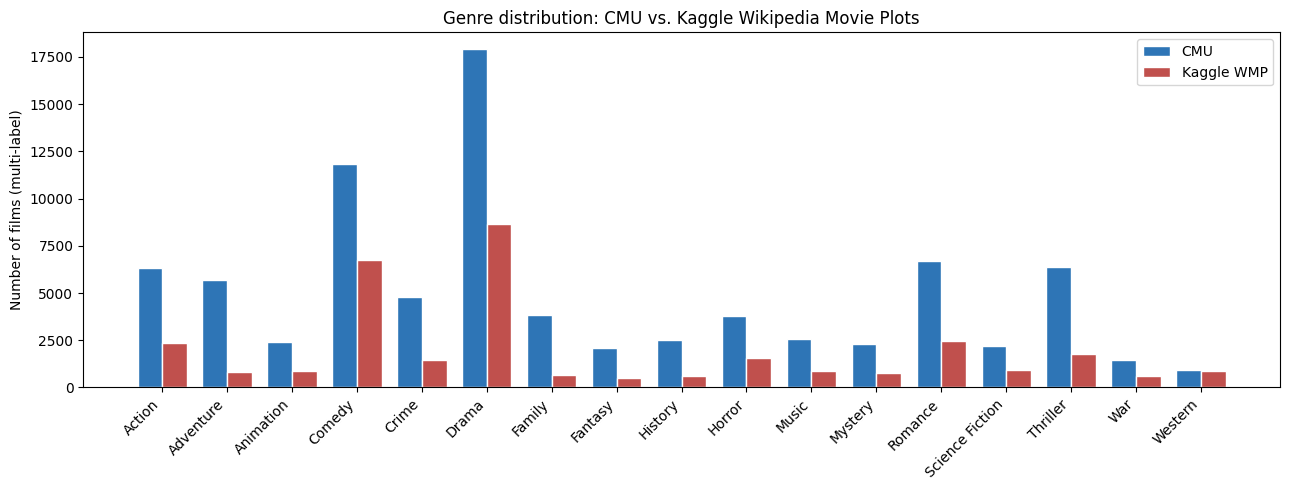


Genre                   CMU   Kaggle    Ratio K/C
------------------------------------------------
Action                6,323    2,362        0.37x
Adventure             5,711      801        0.14x
Animation             2,413      887        0.37x
Comedy               11,838    6,731        0.57x
Crime                 4,797    1,446        0.30x
Drama                17,907    8,662        0.48x
Family                3,811      652        0.17x
Fantasy               2,093      527        0.25x
History               2,515      610        0.24x
Horror                3,794    1,548        0.41x
Music                 2,556      882        0.35x
Mystery               2,321      742        0.32x
Romance               6,717    2,444        0.36x
Science Fiction       2,210      907        0.41x
Thriller              6,363    1,787        0.28x
War                   1,447      586        0.40x
Western                 927      880        0.95x


In [ ]:
# Genre distribution comparison
cmu_canon = Counter()
for glist in cmu['genres_canonical']:
    cmu_canon.update(glist)

kag_canon = Counter()
for glist in cleaned_k['genres_canonical']:
    kag_canon.update(glist)

# Side-by-side bar chart
fig, ax = plt.subplots(figsize=(13, 5))
x = np.arange(len(CANONICAL_GENRES))
width = 0.38
ax.bar(x - width/2, [cmu_canon[g] for g in CANONICAL_GENRES],
       width, label='CMU', color='#2E75B6', edgecolor='white')
ax.bar(x + width/2, [kag_canon[g] for g in CANONICAL_GENRES],
       width, label='Kaggle WMP', color='#C0504D', edgecolor='white')
ax.set_xticks(x)
ax.set_xticklabels(CANONICAL_GENRES, rotation=45, ha='right')
ax.set_ylabel('Number of films (multi-label)')
ax.set_title('Genre distribution: CMU vs. Kaggle Wikipedia Movie Plots')
ax.legend()
plt.tight_layout()
plt.savefig(f'{FIGURES_DIR}/genre_distribution_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

# Tabular
print(f'\n{"Genre":<18} {"CMU":>8} {"Kaggle":>8} {"Ratio K/C":>12}')
print('-' * 48)
for g in CANONICAL_GENRES:
    c = cmu_canon[g]
    k = kag_canon[g]
    ratio = k / c if c > 0 else float('inf')
    print(f'{g:<18} {c:>8,} {k:>8,} {ratio:>11.2f}x')

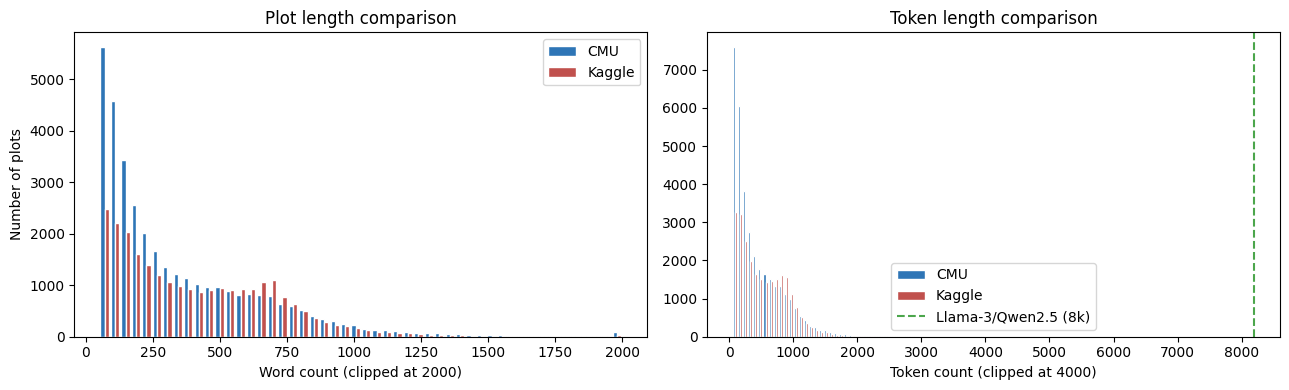


Token count percentiles side by side:
Percentile          CMU     Kaggle
------------------------------------
p50                 294        457
p75                 643        800
p90                 978      1,017
p95               1,189      1,194
p99               1,790      1,685
p99.9             3,139      2,822


In [ ]:
# Plot length comparison
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].hist([cmu['word_count'].clip(upper=2000), cleaned_k['word_count'].clip(upper=2000)],
             bins=50, label=['CMU', 'Kaggle'],
             color=['#2E75B6', '#C0504D'], edgecolor='white')
axes[0].set_xlabel('Word count (clipped at 2000)')
axes[0].set_ylabel('Number of plots')
axes[0].set_title('Plot length comparison')
axes[0].legend()

axes[1].hist([cmu['token_count'].clip(upper=4000), cleaned_k['token_count'].clip(upper=4000)],
             bins=50, label=['CMU', 'Kaggle'],
             color=['#2E75B6', '#C0504D'], edgecolor='white')
axes[1].axvline(8192, color='green', linestyle='--', alpha=0.7, label='Llama-3/Qwen2.5 (8k)')
axes[1].set_xlabel('Token count (clipped at 4000)')
axes[1].set_title('Token length comparison')
axes[1].legend()

plt.tight_layout()
plt.savefig(f'{FIGURES_DIR}/length_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

# Percentile comparison
print(f'\nToken count percentiles side by side:')
print(f'{"Percentile":<12} {"CMU":>10} {"Kaggle":>10}')
print('-' * 36)
for p in [50, 75, 90, 95, 99, 99.9]:
    c_val = np.percentile(cmu['token_count'].dropna(), p)
    k_val = np.percentile(cleaned_k['token_count'].dropna(), p)
    print(f'p{p:<11} {c_val:>10,.0f} {k_val:>10,.0f}')

In [ ]:
from collections import Counter
import pandas as pd

PROJECT_ROOT = '/content/drive/MyDrive/DGK Lab/Reasoning Lab/DGK Lab - Scene A Faire Computational'
kaggle_audited = pd.read_parquet(f'{PROJECT_ROOT}/v4_rebuild/01b_audit_kaggle/kaggle_audited.parquet')

# The saved parquet only contains films that already HAVE canonical genres
# (they got filtered in during save), so we can't diagnose the dropped films from it.
# We need to reload the raw Kaggle CSV and re-canonicalize to see the unmapped labels.

import re
import numpy as np

KAGGLE_CSV_PATH = f'{PROJECT_ROOT}/Data/WikipediaMoviePlots/wiki_movie_plots_deduped.csv'
kaggle = pd.read_csv(KAGGLE_CSV_PATH)
kaggle = kaggle.rename(columns={
    'Release Year': 'year', 'Title': 'name', 'Origin/Ethnicity': 'origin',
    'Director': 'director', 'Cast': 'cast', 'Genre': 'genre_raw',
    'Wiki Page': 'wiki_page', 'Plot': 'plot'
})

def parse_kaggle_genres(genre_str):
    if pd.isna(genre_str) or not genre_str:
        return []
    s = str(genre_str).strip().lower()
    if s in ('unknown', '-', 'none', 'n/a'):
        return []
    parts = re.split(r'[,;/]', s)
    return [p.strip() for p in parts if p.strip()]

kaggle['genres_parsed'] = kaggle['genre_raw'].apply(parse_kaggle_genres)

CANONICAL_GENRES = [
    'Action', 'Adventure', 'Animation', 'Comedy', 'Crime',
    'Drama', 'Family', 'Fantasy', 'History', 'Horror',
    'Music', 'Mystery', 'Romance', 'Science Fiction',
    'Thriller', 'War', 'Western'
]
GENRE_KEYWORDS = {
    'Action':          ['action', 'martial arts'],
    'Adventure':       ['adventure', 'swashbuckler'],
    'Animation':       ['animation', 'animated', 'anime'],
    'Comedy':          ['comedy', 'comic', 'parody', 'satire', 'screwball', 'farce'],
    'Crime':           ['crime', 'gangster', 'heist', 'detective', 'whodunit', 'caper'],
    'Drama':           ['drama', 'melodrama'],
    'Family':          ['family', 'children'],
    'Fantasy':         ['fantasy', 'mythological', 'sword and sorcery'],
    'History':         ['history', 'historical', 'biographical', 'biography', 'period', 'docudrama'],
    'Horror':          ['horror', 'slasher', 'zombie', 'vampire', 'splatter'],
    'Music':           ['music', 'musical', 'concert'],
    'Mystery':         ['mystery', 'noir'],
    'Romance':         ['romance', 'romantic'],
    'Science Fiction': ['science fiction', 'sci-fi', 'scifi', 'cyberpunk', 'space opera'],
    'Thriller':        ['thriller', 'suspense', 'psychological'],
    'War':             ['war', 'military', 'combat'],
    'Western':         ['western']
}

def canonicalize(raw_genres):
    canonical = set()
    for raw in raw_genres:
        raw_lower = str(raw).lower()
        for canon, keywords in GENRE_KEYWORDS.items():
            if any(kw in raw_lower for kw in keywords):
                canonical.add(canon)
    return sorted(canonical)

kaggle['genres_canonical'] = kaggle['genres_parsed'].apply(canonicalize)
kaggle['n_canonical_genres'] = kaggle['genres_canonical'].str.len()

# Now the diagnostic
unmapped = kaggle[(kaggle['n_canonical_genres'] == 0) & (kaggle['genres_parsed'].str.len() > 0)]
print(f'Films with raw genres but zero canonical mapping: {len(unmapped):,}\n')

unmapped_labels = Counter()
for glist in unmapped['genres_parsed']:
    unmapped_labels.update(glist)

print('Top 30 raw labels on films we dropped:')
for label, count in unmapped_labels.most_common(30):
    print(f'  {count:>5,}  {label}')

# Also show how many films had truly empty/unknown genre
truly_empty = kaggle[kaggle['genres_parsed'].str.len() == 0]
print(f'\nFilms with fully unknown/empty genre field: {len(truly_empty):,}')

Films with raw genres but zero canonical mapping: 1,073

Top 30 raw labels on films we dropped:
     85  social
     74  documentary
     71  serial
     58  biopic
     48  superhero
     31  mockumentary
     30  short
     29  tokusatsu
     28  spy
     27  sports
     25  dramedy
     22  mythology
     19  short subject
     17  folklore
     16  masala
     15  science-fiction
     14  rom com
     13  propaganda
     13  kaiju
     12  slapstick
     12  devotional
     11  epic
     11  disaster film
     10  disaster
      9  wuxia
      8  exploitation
      8  bio-pic
      8  sexploitation
      8  adult
      7  short film

Films with fully unknown/empty genre field: 6,114


In [ ]:
import re
from collections import Counter
import numpy as np
import pandas as pd

PROJECT_ROOT = '/content/drive/MyDrive/DGK Lab/Reasoning Lab/DGK Lab - Scene A Faire Computational'
KAGGLE_CSV_PATH = f'{PROJECT_ROOT}/Data/WikipediaMoviePlots/wiki_movie_plots_deduped.csv'
OUTPUT_DIR = f'{PROJECT_ROOT}/v4_rebuild/01b_audit_kaggle'

CANONICAL_GENRES = [
    'Action', 'Adventure', 'Animation', 'Comedy', 'Crime',
    'Drama', 'Family', 'Fantasy', 'History', 'Horror',
    'Music', 'Mystery', 'Romance', 'Science Fiction',
    'Thriller', 'War', 'Western'
]

# Expanded keyword mapper with new entries marked
GENRE_KEYWORDS = {
    'Action':          ['action', 'martial arts', 'superhero', 'wuxia', 'kung fu'],
    'Adventure':       ['adventure', 'swashbuckler', 'epic'],
    'Animation':       ['animation', 'animated', 'anime'],
    'Comedy':          ['comedy', 'comic', 'parody', 'satire', 'screwball', 'farce',
                        'slapstick', 'dramedy', 'rom com', 'rom-com'],
    'Crime':           ['crime', 'gangster', 'heist', 'detective', 'whodunit', 'caper'],
    'Drama':           ['drama', 'melodrama', 'dramedy', 'sports'],
    'Family':          ['family', 'children'],
    'Fantasy':         ['fantasy', 'mythological', 'mythology', 'folklore',
                        'sword and sorcery', 'kaiju'],
    'History':         ['history', 'historical', 'biographical', 'biography', 'biopic',
                        'bio-pic', 'period', 'docudrama'],
    'Horror':          ['horror', 'slasher', 'zombie', 'vampire', 'splatter', 'kaiju'],
    'Music':           ['music', 'musical', 'concert'],
    'Mystery':         ['mystery', 'noir'],
    'Romance':         ['romance', 'romantic', 'rom com', 'rom-com'],
    'Science Fiction': ['science fiction', 'science-fiction', 'sci-fi', 'scifi',
                        'cyberpunk', 'space opera', 'tokusatsu'],
    'Thriller':        ['thriller', 'suspense', 'psychological', 'spy', 'disaster'],
    'War':             ['war', 'military', 'combat'],
    'Western':         ['western']
}

def parse_kaggle_genres(genre_str):
    if pd.isna(genre_str) or not genre_str:
        return []
    s = str(genre_str).strip().lower()
    if s in ('unknown', '-', 'none', 'n/a'):
        return []
    parts = re.split(r'[,;/]', s)
    return [p.strip() for p in parts if p.strip()]

def canonicalize(raw_genres):
    canonical = set()
    for raw in raw_genres:
        raw_lower = str(raw).lower()
        for canon, keywords in GENRE_KEYWORDS.items():
            if any(kw in raw_lower for kw in keywords):
                canonical.add(canon)
    return sorted(canonical)

# Reload and re-canonicalize Kaggle
print('Reloading Kaggle CSV...')
kaggle = pd.read_csv(KAGGLE_CSV_PATH)
kaggle = kaggle.rename(columns={
    'Release Year': 'year', 'Title': 'name', 'Origin/Ethnicity': 'origin',
    'Director': 'director', 'Cast': 'cast', 'Genre': 'genre_raw',
    'Wiki Page': 'wiki_page', 'Plot': 'plot'
})
kaggle['wiki_id'] = kaggle['wiki_page'].apply(
    lambda u: str(u).split('/')[-1] if pd.notna(u) else None
)
kaggle['year'] = pd.to_numeric(kaggle['year'], errors='coerce')
kaggle.loc[(kaggle['year'] < 1890) | (kaggle['year'] > 2025), 'year'] = np.nan
kaggle['decade'] = (kaggle['year'] // 10 * 10).astype('Int64')

kaggle['genres_parsed'] = kaggle['genre_raw'].apply(parse_kaggle_genres)
kaggle['genres_canonical'] = kaggle['genres_parsed'].apply(canonicalize)
kaggle['n_canonical_genres'] = kaggle['genres_canonical'].str.len()

# Before/after comparison
with_canonical = (kaggle['n_canonical_genres'] > 0).sum()
print(f'\nAfter expanded mapping:')
print(f'  Films with canonical genre: {with_canonical:,} (was 27,699)')
print(f'  Recovered: {with_canonical - 27699:,} additional films')

# Still-unmapped diagnostic
unmapped = kaggle[(kaggle['n_canonical_genres'] == 0) & (kaggle['genres_parsed'].str.len() > 0)]
print(f'\nStill-unmapped films with raw genres: {len(unmapped):,}')
unmapped_labels = Counter()
for glist in unmapped['genres_parsed']:
    unmapped_labels.update(glist)
print('\nTop 15 still-unmapped labels:')
for label, count in unmapped_labels.most_common(15):
    print(f'  {count:>5,}  {label}')

# Updated canonical distribution
canon_counter = Counter()
for glist in kaggle['genres_canonical']:
    canon_counter.update(glist)
print(f'\nUpdated Kaggle canonical distribution:')
for genre in CANONICAL_GENRES:
    print(f'  {genre:<18} {canon_counter[genre]:>6,}')

# Re-compute length columns and save new parquet
kaggle['char_count'] = kaggle['plot'].str.len().fillna(0).astype(int)
kaggle['word_count'] = kaggle['plot'].str.split().str.len().fillna(0).astype(int)

try:
    import tiktoken
    enc = tiktoken.get_encoding('cl100k_base')
    kaggle['token_count'] = kaggle['plot'].apply(
        lambda x: len(enc.encode(x)) if isinstance(x, str) and x else 0
    )
except ImportError:
    kaggle['token_count'] = (kaggle['word_count'] * 1.33).astype(int)

cleaned_k = kaggle[
    (kaggle['word_count'] >= 50) &
    (kaggle['n_canonical_genres'] > 0) &
    (kaggle['plot'].notna()) &
    (kaggle['plot'].str.len() > 0)
].copy()

keep_cols = [
    'wiki_id', 'name', 'year', 'decade',
    'plot', 'char_count', 'word_count', 'token_count',
    'genres_parsed', 'genres_canonical', 'n_canonical_genres',
    'origin', 'director'
]
cleaned_k = cleaned_k[keep_cols].reset_index(drop=True)

output_path = f'{OUTPUT_DIR}/kaggle_audited.parquet'
cleaned_k.to_parquet(output_path, engine='pyarrow', compression='snappy')
print(f'\nSaved updated parquet: {output_path}')
print(f'  Rows: {len(cleaned_k):,}  (was 25,557)')

Reloading Kaggle CSV...

After expanded mapping:
  Films with canonical genre: 28,093 (was 27,699)
  Recovered: 394 additional films

Still-unmapped films with raw genres: 679

Top 15 still-unmapped labels:
     84  social
     74  documentary
     71  serial
     31  mockumentary
     30  short
     19  short subject
     16  masala
     13  propaganda
     12  devotional
      8  exploitation
      8  sexploitation
      8  adult
      7  short film
      7  anthology
      7  religious

Updated Kaggle canonical distribution:
  Action              2,596
  Adventure             913
  Animation             909
  Comedy              7,363
  Crime               1,635
  Drama               9,571
  Family                684
  Fantasy               607
  History               743
  Horror              1,627
  Music                 967
  Mystery               838
  Romance             2,639
  Science Fiction       986
  Thriller            2,074
  War                   617
  Western         

## 9. Decisions for Notebook 02

Based on the outputs above, answer:

**Q1: Does Kaggle actually extend the temporal range?** Look at the decade comparison. If Kaggle has substantially more films in the 2010s than CMU, it's a real extension. If not, it's just a replication corpus without adding years.

**Q2: How much do the corpora overlap?** The fuzzy title+year match gives us an estimate. If overlap is 60-80%, they're largely the same data with different coverage at the edges (expected, both draw from Wikipedia). If overlap is below 30%, they're surprisingly different and we should investigate why before trusting either.

**Q3: Are genre distributions similar?** Look at the K/C ratio column. Ratios near 1.0 mean the two corpora agree on relative genre proportions. Ratios far from 1.0 in specific genres signal that one corpus systematically under- or over-represents that genre, which matters for how we interpret replication.

**Q4: Primary corpus strategy.** Based on the above, pick one:
- **CMU-primary with Kaggle replication:** Use CMU for main findings, report that headline results replicate on Kaggle. Standard approach, defensible, and what most reviewers will expect.
- **Union corpus:** Deduplicate across the two corpora, use the combined set as primary. Larger N, but introduces handling complexity for differences in metadata quality.
- **Kaggle-primary:** Switch entirely to Kaggle if it's substantially better coverage and cleaner.

My prior is CMU-primary with Kaggle replication, but the data shown above should drive the call.

Once we've picked, Notebook 02 builds element extraction on the chosen primary corpus. Notebook 02 will include the regex cleaning pass to strip broken wiki markup (`[[`, `]]`, templates) before spaCy sees the plot text.